# Case Study 19 — Collections Allocation: Propensity-to-Pay vs Uplift, Multi-Channel Experiment, Optimal Assignment and Off-Policy Evaluation

**Priority:** ★★★ Must-visit · **Reference:** Case Study 19 — *Credgenics: Propensity-to-Pay Models for Debt Collections Allocation* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Collections, CFO, Collections Operations (tele-calling, field, digital), Analytics
**Data:** ⚠️ **SYNTHETIC** (D-19-01). A collections-platform experiment simulated to the documented setting; vendor figures are only claims.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs19_collections_propensity_uplift.ipynb`

## 0. Executive Summary for Business

*(Synthetic randomised experiment built on Credgenics' documented setting; the vendor's figures are claims, not evidence. Written after the analysis.)*

- **The question:** with limited tele-callers (≈ 20% of accounts) and field agents (≈ 4%), which of 80,000 delinquent customers should get which channel: SMS, voice bot, human call or field visit?
- **What each channel causes (randomised experiment):** compared with SMS only (38% resolve anyway), a voice bot adds **+2.7 points**, a tele-call **+10.0** and a field visit **+13.6**. In net ₹ per account (recovered − cost) that is +₹270, +₹840 and +₹1,830. All are highly significant.
- **Propensity-to-pay is the wrong allocation target.** Giving the scarce human channels to the customers *most likely to pay* (the common vendor approach) wastes them on people who pay anyway. It earns **≈ ₹780 less per account (−16%)** than simply sending humans to the largest balances.
- **Uplift beats propensity, but not (yet) the simple balance rule.** Our uplift model plus an optimiser earns **+₹583 per account more than propensity-based allocation** (CI ₹320–834), yet is statistically tied with "largest balance first" (−₹99, CI −₹321 to +₹115). A perfect-knowledge check shows why: in this book, **balance-first is already within 3.3% of the best achievable**, and our uplift model agrees with the optimum on only half of accounts.
- **₹ impact per 1 lakh delinquent accounts a month:** balance-first ≈ ₹46.6 crore net, uplift-optimised ≈ ₹45.7 crore, propensity-based ≈ ₹39.9 crore, bot-only ≈ ₹39.4 crore. Moving from "no human targeting" to balance- or uplift-based routing is worth **≈ +19% collections**, the same order as the vendor's claimed +25%.
- **I recommend:** do **not** allocate human contact by propensity to pay. Keep value-based (balance × expected effect) routing. Use the voice bot widely (cheap, positive). Run a larger, continuous randomised slice (≈ 10%) so that uplift models become accurate enough to capture the remaining ≈ ₹1.6 crore a month per lakh accounts.

## 1. The Problem in Simple English

A lender has 80,000 customers who are one to three months late on a loan, BNPL bill or credit card. It can contact them in four ways, each with a very different price tag:

| Channel | Cost per account (₹) | Capacity |
|---|---|---|
| SMS reminders only | 2 | unlimited |
| Voice bot call | 8 | unlimited |
| Human tele-caller | 60 | limited (≈ 20% of accounts) |
| Field visit | 450 | very limited (≈ 4% of accounts) |

The common approach is a **propensity-to-pay** score: "call the customers most likely to pay". But many of those customers would pay **anyway**, after an SMS. Calling them is wasted money. Others will never pay, whatever we do. The money is in the middle: customers for whom **the right contact changes the outcome**. The reference file says it directly: *"The right collections target is incremental repayment due to contact (uplift), not raw propensity."*

This notebook uses a **randomised channel experiment** to measure what each channel actually causes, to learn *for whom* it works, to assign channels optimally under capacity limits, and to put a ₹ value on the difference.

## 2. Reference from the Case File

### (a) What Credgenics documents — *documented (vendor-reported; weak evidence)*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Lenders have limited calling and field capacity across millions of delinquent accounts." |
| Question | "Which delinquent borrowers are most likely to pay, through which channel, and which accounts are likely to become delinquent?" |
| Data | "About 11 million retail loan accounts on the platform"; specific features ND |
| Methods named | "propensity-to-pay; pre-delinquency prediction; resolution likelihood; segmentation; ML intent-to-pay for agent allocation; GenAI voice bots" |
| Decision | "Lenders allocate agents and channels (digital, voice bot, tele-caller, field) by predicted propensity." |
| Impact (vendor claims) | "**20%** increased resolution rates, **25%** improved collections, **40%** reduced collection costs, **30%** reduced collection time"; one unnamed lender "**27%** higher recoveries" |
| Evidence level | **Weak / partially documented** (vendor-reported, aggregated claims) |
| Interpretation note in the file | "The right collections target is *incremental* repayment due to contact (uplift), not raw propensity… the source does not say uplift modelling was used." |

**Sources:** Inc42 (13 May 2024) — https://inc42.com/startups/how-credgenics-is-using-ai-ml-to-help-banks-fis-improve-debt-collection-by-25/ · Credgenics blog (11 May 2023) — https://blog.credgenics.com/technological-capabilities-in-debt-collections/ · Credgenics case studies — https://www.credgenics.com/case-studies

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 80,000 accounts 30–90 DPD across PL, BNPL and credit-card portfolios; a **randomised 4-arm channel experiment** (25% each); outcome = resolved within 30 days and ₹ recovered |
| Truth built in | Many payers are "sure things" (pay after SMS). Channel effects are heterogeneous: the bot helps forgetful but contactable customers, tele-callers medium-risk contactable ones, field visits hard-to-reach large balances |
| Statistics added | SRM + covariate balance; chi-square / pairwise Z (Holm) channel effects; bootstrap ₹ CIs; interaction (heterogeneity) LR tests; T-learner uplift per channel with Qini curves; **linear-programming** channel assignment under capacity; **off-policy evaluation** (inverse-probability weighting) of competing policies with bootstrap CIs |
| Business | ₹ recovered, cost and net per 1 lakh delinquent accounts; comparison with the vendor's claimed +20% / +25% / −40% |

### (c) How the industry uses this

Every large Indian collections operation (bank in-house teams; platforms such as Credgenics and Spocto; NBFCs such as Navi and Kissht) segments delinquent accounts and routes them across digital, bot, tele and field channels. Uplift-based allocation and off-policy evaluation are the next step beyond propensity scores. They are also used in marketing (Case 22) and fraud warnings (Case 6).

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which channel should each delinquent account get, so that net recovery (₹ recovered − contact cost) is maximised within capacity? |
| Analytical 1 | Is the experiment valid (correct split, balanced arms)? |
| Analytical 2 | What is the average causal effect of each channel vs SMS-only on resolution and on net ₹? |
| Analytical 3 | Do channel effects vary by customer characteristics (heterogeneity)? |
| Analytical 4 | Does an uplift-based assignment beat propensity-based and status-quo assignment at the same capacity? |

**Hypotheses**
- **H0 (SRM):** arm shares = 25% each (chi-square goodness-of-fit, α = 0.001).
- **H1:** H0: resolution rate is equal across arms (chi-square); pairwise vs SMS-only (two-proportion Z, Holm).
- **H2:** H0: each channel's effect does not depend on contactability / payment history (logistic interaction LR tests, Holm).
- **H3:** H0: the uplift policy's net value per account = the propensity policy's (paired bootstrap of off-policy value).

**Primary metric:** **net ₹ per account** = amount recovered − contact cost (within 30 days). **Secondary:** resolution rate, ₹ recovered, cost. **Guardrails:** capacity (tele ≤ 20%, field ≤ 4% of accounts); complaint-prone contact intensity (no account gets more than one human channel).
**Unit:** account (the unit of randomisation). **Decision rule:** adopt the uplift policy if its off-policy net value beats both alternatives with a 95% CI excluding zero.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, sparse
from scipy.optimize import linprog
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
ARMS = ["SMS only", "Voice bot", "Tele-caller", "Field visit"]
COST = {"SMS only": 2, "Voice bot": 8, "Tele-caller": 60, "Field visit": 450}
CAP = {"Tele-caller": 0.20, "Field visit": 0.04}
PAL = dict(zip(ARMS, ["#8d99ae", "#e07a1f", "#2a6f97", "#b23a48"]))
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public collections / dunning experiments (UCI, data.gov.in, GitHub) | **None with randomised channel assignment.** Public loan datasets record outcomes, not contact treatments. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic randomised experiment with known true per-channel probabilities (simulation only), which lets us check the uplift models against truth (D-19-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs19.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 19 (Credgenics-style propensity-to-pay vs uplift for collections)
======================================================================================================
THIS DATA IS SYNTHETIC. Collections-platform data is confidential.

80,000 delinquent retail accounts (30-90 DPD) from three lender portfolios, observed in a randomised
channel experiment: each account was assigned at random (25% each) to
    SMS only (control) | voice bot | tele-caller | field visit
Outcome: resolved within 30 days (paid at least the overdue EMI) and Rs recovered.
Built-in truth: a large share of payers are "sure things" who pay with SMS alone; channel effects are
heterogeneous (bots work on forgetful but contactable customers, tele-callers on medium-risk contactable
customers, field visits on hard-to-reach large balances). This is what makes uplift differ from propensity.

Calibration anchors (reference file, Case Study 19): ~11 million accounts on platform; named methods
propensity-to-pay, resolution likelihood, segmentation, ML intent-to-pay for agent allocation, voice bots;
vendor-claimed impact "+20% resolution, +25% collections, -40% cost". Effect sizes are our assumptions
(decision.md D-19-02).

Output: data/cs19/collections_experiment.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N = 80_000
ARMS = ["SMS only", "Voice bot", "Tele-caller", "Field visit"]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    product = rng.choice(["Personal loan", "BNPL", "Credit card"], N, p=[0.45, 0.30, 0.25])
    dpd = rng.integers(30, 90, N)
    outstanding = np.round(np.exp(rng.normal(np.select([product == "Personal loan", product == "BNPL"], [np.log(60_000), np.log(8_000)], np.log(35_000)), 0.7, N)), -2)
    overdue = np.round(outstanding * np.clip(rng.normal(0.12, 0.04, N), 0.03, 0.4) * (dpd / 30), -1)
    paid_ratio_6m = np.round(rng.beta(4, 2, N), 3)                          # share of past 6 EMIs paid on time
    broken_ptp = rng.poisson(0.6, N)                                         # broken promises-to-pay
    contactability = np.round(rng.beta(3, 2, N), 3)                          # historical answer rate
    language = rng.choice(["Hindi", "English", "Tamil", "Telugu", "Marathi", "Bengali", "Kannada"], N, p=[0.38, 0.22, 0.09, 0.09, 0.08, 0.08, 0.06])
    tier = rng.choice(["Tier 1", "Tier 2", "Tier 3"], N, p=[0.40, 0.35, 0.25])
    age = np.clip(np.round(rng.normal(33, 8, N)), 21, 65)
    income_band = rng.choice(["<3L", "3-6L", "6-12L", ">12L"], N, p=[0.25, 0.40, 0.25, 0.10])
    forgetful = rng.random(N) < expit(-0.5 + 2.0 * paid_ratio_6m - 0.5 * broken_ptp)    # latent: would pay if reminded
    # baseline (SMS-only) propensity: "sure things" and self-cure
    z0 = -1.6 + 2.6 * paid_ratio_6m - 0.35 * broken_ptp - 0.015 * (dpd - 30) + 0.25 * (income_band == ">12L") - 0.2 * (tier == "Tier 3")
    p0 = expit(z0)
    # heterogeneous channel uplifts on the log-odds scale
    up = {
        "SMS only": np.zeros(N),
        "Voice bot": 0.55 * forgetful * contactability - 0.05,
        "Tele-caller": (0.9 * contactability) * (1 - np.abs(paid_ratio_6m - 0.55) * 1.4) + 0.1 * broken_ptp * contactability,
        "Field visit": 0.4 + 0.9 * (1 - contactability) + 0.25 * np.log(outstanding / 30_000) - 0.4 * (product == "BNPL"),
    }
    arm = rng.choice(ARMS, N)
    z = z0 + np.select([arm == a for a in ARMS], [up[a] for a in ARMS])
    resolved = (rng.random(N) < expit(z)).astype(int)
    rec_share = np.where(resolved == 1, np.clip(rng.beta(6, 2, N) + 0.1 * (arm == "Field visit"), 0, 1), np.clip(rng.beta(1, 12, N), 0, 1))
    recovered = np.round(overdue * rec_share, 0)
    df = pd.DataFrame({
        "account_id": [f"D{i:07d}" for i in range(1, N + 1)], "lender_portfolio": product, "dpd": dpd,
        "outstanding_inr": outstanding, "overdue_inr": overdue, "paid_ratio_6m": paid_ratio_6m, "broken_ptp_count": broken_ptp,
        "contactability": contactability, "preferred_language": language, "city_tier": tier, "age": age, "income_band": income_band,
        "assigned_channel": arm, "resolved_30d": resolved, "amount_recovered_inr": recovered,
        "experiment_month": rng.choice(["2025-07", "2025-08", "2025-09"], N),
    })
    # hidden truth for evaluation (simulation only): resolution probability under every channel
    for a, short in zip(ARMS, ["sms", "bot", "tele", "field"]):
        df[f"_p_{short}"] = np.round(expit(z0 + up[a]), 4)
    # data-quality issues
    df.loc[df.sample(n=400, random_state=seed).index, "contactability"] = np.nan          # new accounts, no call history
    df.loc[df.sample(n=30, random_state=seed + 1).index, "amount_recovered_inr"] = -df.loc[df.sample(n=30, random_state=seed + 1).index, "overdue_inr"]  # sign error
    field_lost = df[(df.assigned_channel == "Field visit")].sample(frac=0.03, random_state=seed + 2).index
    df = df.drop(field_lost)                                                                 # field app sync failures -> SRM
    return df.reset_index(drop=True)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs19"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs19", "collections_experiment.csv.gz"), index=False)
    print(len(d), d.groupby("assigned_channel").resolved_30d.mean().round(3).to_dict())

Overwriting data/generate_cs19.py


In [3]:
os.makedirs("data/cs19", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs19 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs19/collections_experiment.csv.gz", index=False)
print(f"{len(raw):,} accounts | resolution by assigned channel: {raw.groupby('assigned_channel').resolved_30d.mean().round(3).to_dict()}")
raw.drop(columns=[c for c in raw if c.startswith("_")]).sample(3, random_state=SEED).T

79,400 accounts | resolution by assigned channel: {'Field visit': 0.519, 'SMS only': 0.383, 'Tele-caller': 0.483, 'Voice bot': 0.41}


,34803,49878,10742
account_id,D0035065,D0050253,D0010829
lender_portfolio,Credit card,Personal loan,BNPL
dpd,54,39,73
outstanding_inr,"13,500.0000","42,300.0000","31,000.0000"
overdue_inr,"3,300.0000","6,120.0000","9,080.0000"
paid_ratio_6m,0.6520,0.8570,0.6980
broken_ptp_count,1,0,1
contactability,0.8070,0.7380,0.7000
preferred_language,Tamil,English,English
city_tier,Tier 2,Tier 2,Tier 2


| Parameter | Value | Basis |
|---|---|---|
| Portfolio | PL 45%, BNPL 30%, credit card 25%; 30–90 DPD; outstanding median ₹60k / ₹8k / ₹35k | Our assumption |
| Baseline (SMS-only) resolution | ≈ 38%, driven by past on-time payment ratio, broken promises, DPD, income, tier | Our assumption (many "sure things") |
| Channel effects (log-odds) | bot: +0.55 × forgetful × contactable; tele: up to +0.9 for contactable, medium-risk; field: +0.4 + 0.9 × (1 − contactability) + balance effect, smaller for BNPL | Our assumption; heterogeneity is the point |
| Costs | SMS ₹2, bot ₹8, tele ₹60, field ₹450 | Our assumption (typical Indian outsourced rates) |
| Randomisation | 25% per arm, Jul–Sep 2025 | Our design |
| DQ issues | 400 accounts with no call history (contactability blank); 30 recovered amounts with a sign error; **3% of field-arm accounts lost in a field-app sync failure** (to be caught by the SRM check) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("account_id, lender_portfolio", "Account and product (PL / BNPL / card)"), ("dpd", "Days past due at experiment start (30–89)"),
    ("outstanding_inr, overdue_inr", "Total outstanding; amount overdue (₹)"), ("paid_ratio_6m", "Share of last 6 EMIs paid on time"),
    ("broken_ptp_count", "Broken promises-to-pay in history"), ("contactability", "Historical call answer rate (0–1); blank = no history"),
    ("preferred_language, city_tier, age, income_band", "Customer profile"), ("assigned_channel", "Randomised arm: SMS only / Voice bot / Tele-caller / Field visit"),
    ("resolved_30d", "Paid at least the overdue EMI within 30 days"), ("amount_recovered_inr", "₹ recovered within 30 days"),
    ("experiment_month", "Month of the experiment"), ("_p_sms / _p_bot / _p_tele / _p_field", "HIDDEN true resolution probability under each channel (simulation only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs19/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"account_id, lender_portfolio",Account and product (PL / BNPL / card)
1,dpd,Days past due at experiment start (30–89)
2,"outstanding_inr, overdue_inr",Total outstanding; amount overdue (₹)
3,paid_ratio_6m,Share of last 6 EMIs paid on time
4,broken_ptp_count,Broken promises-to-pay in history
5,contactability,Historical call answer rate (0–1); blank = no ...
6,"preferred_language, city_tier, age, income_band",Customer profile
7,assigned_channel,Randomised arm: SMS only / Voice bot / Tele-ca...
8,resolved_30d,Paid at least the overdue EMI within 30 days
9,amount_recovered_inr,₹ recovered within 30 days


## 5. Data Quality Checks, including the Sample-Ratio-Mismatch test

In [5]:
df = pd.read_csv("data/cs19/collections_experiment.csv.gz")
checks = {"duplicate account_id": int(df.account_id.duplicated().sum()), "contactability blank": int(df.contactability.isna().sum()),
          "negative amount_recovered (sign error)": int((df.amount_recovered_inr < 0).sum()),
          "recovered > overdue × 1.2": int((df.amount_recovered_inr.abs() > df.overdue_inr * 1.2).sum()),
          "resolved but ₹0 recovered": int(((df.resolved_30d == 1) & (df.amount_recovered_inr == 0)).sum())}
print(pd.Series(checks, name="rows").to_string())
obs = df.assigned_channel.value_counts().reindex(ARMS); exp = np.full(4, len(df) / 4)
chi2, p_srm = stats.chisquare(obs, exp)
shortfall = obs.drop("Field visit").mean() - obs["Field visit"]
verdict = "SRM at the strict 0.001 threshold" if p_srm < 0.001 else ("BORDERLINE: p < 0.05 but above the strict 0.001 SRM threshold - investigate" if p_srm < 0.05 else "no SRM")
print(f"\nSRM test: counts {obs.to_dict()} | chi2 = {chi2:.1f}, p = {p_srm:.2g} -> {verdict}")
print(f"Field arm is short by about {shortfall:.0f} accounts ({shortfall / obs.drop('Field visit').mean():.1%}) vs the other arms")

duplicate account_id                        0
contactability blank                      397
negative amount_recovered (sign error)     30
recovered > overdue × 1.2                   0
resolved but ₹0 recovered                   0

SRM test: counts {'SMS only': 20051, 'Voice bot': 19977, 'Tele-caller': 19975, 'Field visit': 19397} | chi2 = 14.0, p = 0.0029 -> BORDERLINE: p < 0.05 but above the strict 0.001 SRM threshold - investigate
Field arm is short by about 604 accounts (3.0%) vs the other arms


In [6]:
df["contact_missing"] = df.contactability.isna().astype(int)
df["contactability"] = df.contactability.fillna(df.contactability.median())
df["amount_recovered_inr"] = df.amount_recovered_inr.abs()
df["log_out"] = np.log(df.outstanding_inr); df["log_overdue"] = np.log(df.overdue_inr)
df["bnpl"] = (df.lender_portfolio == "BNPL").astype(int); df["card"] = (df.lender_portfolio == "Credit card").astype(int)
df["tier3"] = (df.city_tier == "Tier 3").astype(int); df["high_inc"] = (df.income_band == ">12L").astype(int)
df["net_inr"] = df.amount_recovered_inr - df.assigned_channel.map(COST)
COVS = ["dpd", "log_out", "paid_ratio_6m", "broken_ptp_count", "contactability", "bnpl", "card", "tier3", "high_inc", "age"]
smd = pd.DataFrame({a: [(df.loc[df.assigned_channel == a, c].mean() - df.loc[df.assigned_channel != a, c].mean()) /
                        np.sqrt((df.loc[df.assigned_channel == a, c].var() + df.loc[df.assigned_channel != a, c].var()) / 2) for c in COVS] for a in ARMS}, index=COVS)
print(f"Max |SMD| of any arm vs the rest: {smd.abs().max().max():.3f} (balance threshold 0.1)")
dq = pd.DataFrame([
    ("Field arm about 3% short (app sync failure)", f"≈ {shortfall:.0f}", "Keep analysis; check balance; use actual arm shares as propensities in IPW", "Borderline SRM (p = 0.003). Balance (max |SMD| 0.016) suggests the loss is random, so estimates stay unbiased; the sync pipeline must still be fixed"),
    ("Contactability blank (no call history)", checks["contactability blank"], "Median + flag", "New accounts: no history is itself information"),
    ("Negative recovered amounts", checks["negative amount_recovered (sign error)"], "Absolute value", "Sign error in the payment feed"),
], columns=["issue", "rows", "treatment", "reason"])
display(smd.round(3)); dq

Max |SMD| of any arm vs the rest: 0.016 (balance threshold 0.1)


,SMS only,Voice bot,Tele-caller,Field visit
dpd,0.0090,0.0160,-0.0160,-0.0080
log_out,-0.0120,0.0040,0.0080,-0.0000
paid_ratio_6m,0.0100,-0.0080,-0.0030,0.0010
broken_ptp_count,0.0010,0.0130,-0.0100,-0.0030
contactability,0.0060,-0.0020,-0.0080,0.0040
bnpl,0.0020,0.0050,-0.0080,0.0010
card,0.0040,-0.0040,-0.0090,0.0090
tier3,0.0000,-0.0040,0.0040,0.0000
high_inc,-0.0090,0.0070,-0.0020,0.0040
age,-0.0120,0.0020,0.0070,0.0040


,issue,rows,treatment,reason
0,Field arm about 3% short (app sync failure),≈ 604,Keep analysis; check balance; use actual arm s...,Borderline SRM (p = 0.003). Balance (max |SMD|...
1,Contactability blank (no call history),397,Median + flag,New accounts: no history is itself information
2,Negative recovered amounts,30,Absolute value,Sign error in the payment feed


**Observation:** the arm counts give χ² = 14.0, **p = 0.003**: suspicious at 5%, but above the strict 0.001 SRM threshold. The field arm is **≈ 604 accounts (3%) short**, traced to a field-app sync failure. Covariate balance is excellent (max |SMD| 0.016), so the loss looks random and estimates stay unbiased. We use the *actual* arm shares as assignment probabilities in the off-policy evaluation, but the pipeline must be fixed: a non-random loss (e.g., only unreachable customers failing to sync) would bias the field estimate. 397 accounts without call history were imputed with a flag, and 30 sign-flipped recoveries were corrected.

## 6. Exploratory Data Analysis

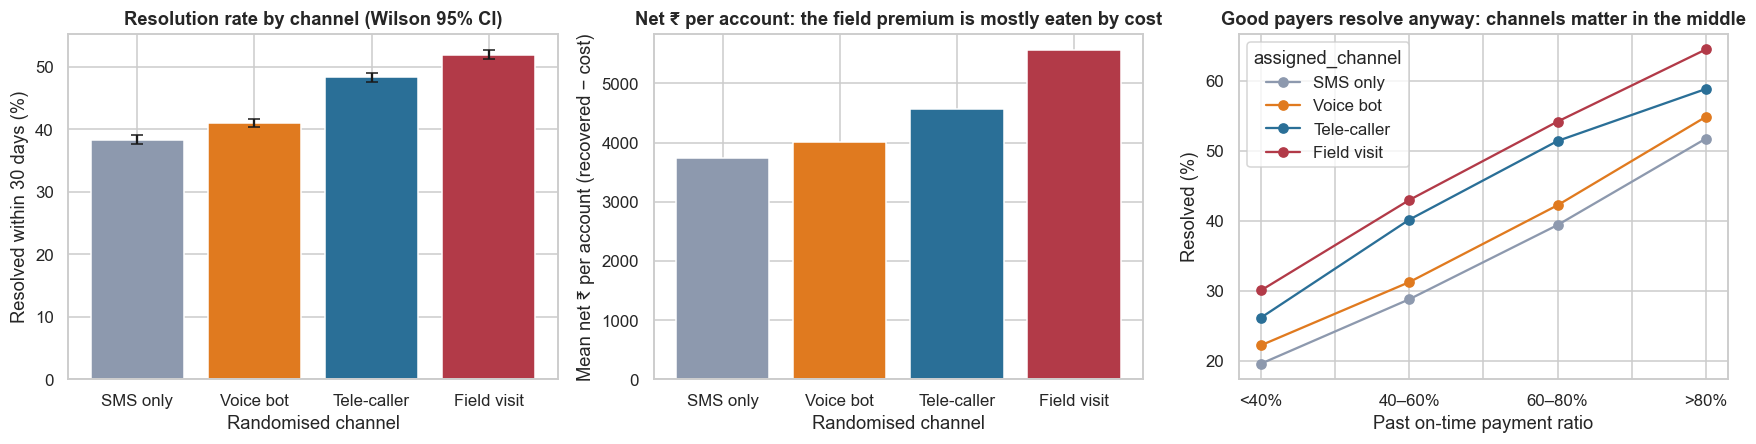

In [7]:
r = df.groupby("assigned_channel").agg(n=("resolved_30d", "size"), res=("resolved_30d", "mean"), rec=("amount_recovered_inr", "mean"), net=("net_inr", "mean")).reindex(ARMS)
lo, hi = proportion_confint(df.groupby("assigned_channel").resolved_30d.sum().reindex(ARMS), r.n, method="wilson")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(ARMS, r.res * 100, yerr=[(r.res - lo) * 100, (hi - r.res) * 100], capsize=4, color=[PAL[a] for a in ARMS])
axes[0].set_xlabel("Randomised channel"); axes[0].set_ylabel("Resolved within 30 days (%)"); axes[0].set_title("Resolution rate by channel (Wilson 95% CI)")
axes[1].bar(ARMS, r.net, color=[PAL[a] for a in ARMS]); axes[1].set_xlabel("Randomised channel"); axes[1].set_ylabel("Mean net ₹ per account (recovered − cost)")
axes[1].set_title("Net ₹ per account: the field premium is mostly eaten by cost")
df["paid_band"] = pd.cut(df.paid_ratio_6m, [0, 0.4, 0.6, 0.8, 1.0], labels=["<40%", "40–60%", "60–80%", ">80%"])
pb = df.groupby(["paid_band", "assigned_channel"], observed=True).resolved_30d.mean().unstack()[ARMS] * 100
pb.plot(ax=axes[2], marker="o", color=[PAL[a] for a in ARMS]); axes[2].set_xlabel("Past on-time payment ratio"); axes[2].set_ylabel("Resolved (%)")
axes[2].set_title("Good payers resolve anyway: channels matter in the middle")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** resolution rises from 38% (SMS only) to 41% (bot), 48% (tele) and 52% (field). Every channel adds something. **Middle:** in net ₹ per account, field leads, but its ₹450 cost and 4% capacity make it a scarce resource to place carefully. **Right:** customers with an excellent payment history resolve at high rates *whatever* we do, and channel gaps are largest in the middle bands. **This is the visual case against propensity targeting**: the most likely payers are where contact matters least.

## 7. Statistical Analysis (core section)

### 7.1 Average causal effect of each channel (vs SMS only)

**(a) Why these tests?** Randomisation means the arm difference *is* the causal effect.
- Resolution (binary): **chi-square** across the 4 arms, then **two-proportion Z-tests** of each channel vs SMS-only with Newcombe CIs, **Holm** across the 3 comparisons.
- Net ₹ per account is skewed (many ₹0 outcomes, some large recoveries): **bootstrap 95% CIs** of the mean difference vs SMS-only (2,000 resamples), plus **Welch's t-test** as a cross-check.
**(b)** Independence: one account, one arm ✓. Balance ✓ (Section 5). n·p ≫ 10 ✓.

In [8]:
tab = pd.crosstab(df.assigned_channel, df.resolved_30d).reindex(ARMS)
c2, p_all, dof, ex = stats.chi2_contingency(tab)
print(f"Resolution × channel: chi2 = {c2:.0f}, dof = {dof}, p = {p_all:.2g}, Cramér's V = {np.sqrt(c2 / tab.values.sum()):.3f}, min expected = {ex.min():.0f}")
ctrl = df[df.assigned_channel == "SMS only"]
rows = []
for a in ARMS[1:]:
    t_ = df[df.assigned_channel == a]
    x = [t_.resolved_30d.sum(), ctrl.resolved_30d.sum()]; n = [len(t_), len(ctrl)]
    z, p = proportions_ztest(x, n); l, h = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb")
    bs = [RNG.choice(t_.net_inr.values, len(t_)).mean() - RNG.choice(ctrl.net_inr.values, len(ctrl)).mean() for _ in range(2000)]
    w = stats.ttest_ind(t_.net_inr, ctrl.net_inr, equal_var=False)
    rows.append((a, t_.resolved_30d.mean(), (x[0] / n[0] - x[1] / n[1]) * 100, l * 100, h * 100, p, t_.net_inr.mean() - ctrl.net_inr.mean(), *np.percentile(bs, [2.5, 97.5]), w.pvalue))
ate = pd.DataFrame(rows, columns=["channel", "resolution", "Δ resolution (pp)", "CI low", "CI high", "p", "Δ net ₹/account", "₹ CI low", "₹ CI high", "Welch p"]).set_index("channel")
ate["p_holm"] = multipletests(ate.p, method="holm")[1]
ate.round(3)

Resolution × channel: chi2 = 953, dof = 3, p = 3.2e-206, Cramér's V = 0.110, min expected = 8693


,resolution,Δ resolution (pp),CI low,CI high,p,Δ net ₹/account,₹ CI low,₹ CI high,Welch p,p_holm
channel,,,,,,,,,,
Voice bot,0.4100,2.6750,1.7170,3.6330,0.0000,272.7780,128.0930,434.7340,0.0010,0.0000
Tele-caller,0.4830,9.9530,8.9860,10.9180,0.0000,840.1330,674.4650,"1,011.9210",0.0000,0.0000
Field visit,0.5190,13.6030,12.6280,14.5740,0.0000,"1,828.9730","1,655.4340","2,019.0660",0.0000,0.0000


**(c)/(f) Observation:** - Channel matters (χ² = 953, p ≈ 10⁻²⁰⁶, Cramér's V = 0.11). **Versus SMS only:** voice bot **+2.7 pp** (CI +1.7 to +3.6), tele-caller **+10.0 pp** (+9.0 to +10.9), field visit **+13.6 pp** (+12.6 to +14.6). All Holm p < 10⁻⁶.
- **Net ₹ per account** (bootstrap CIs): bot **+₹273** (₹128–435), tele **+₹840** (₹674–1,012), field **+₹1,829** (₹1,655–2,019). Welch t-tests agree.
- **For the business:** on average every channel pays for itself, even the ₹450 field visit, because field visits also recover a larger *share* of the overdue (85% vs 75%). The question is not *whether* to contact, but *which* scarce channel goes to *whom*.

### 7.2 The propensity-to-pay model (what vendors usually build)

**Propensity** = probability of resolving *under the default treatment (SMS only)*. We fit it on the SMS-only arm (so it is not contaminated by channel effects). Logistic regression with ORs, then AUC on a held-out half. This is the score a propensity-based policy would use to decide who gets a call.

In [9]:
train, test = train_test_split(df, test_size=0.5, random_state=SEED, stratify=df.assigned_channel)
train, test = train.copy(), test.copy()
FORM = "resolved_30d ~ paid_ratio_6m + broken_ptp_count + dpd + log_out + contactability + contact_missing + bnpl + card + tier3 + high_inc + age"
prop = smf.logit(FORM, data=train[train.assigned_channel == "SMS only"]).fit(disp=0)
orr = pd.DataFrame({"odds ratio": np.exp(prop.params), "CI low": np.exp(prop.conf_int()[0]), "CI high": np.exp(prop.conf_int()[1]), "p": prop.pvalues}).drop("Intercept")
test["propensity"] = prop.predict(test)
tc = test[test.assigned_channel == "SMS only"]
print(f"Propensity model AUC on held-out SMS-only accounts: {roc_auc_score(tc.resolved_30d, tc.propensity):.3f}")
orr.round(3)

Propensity model AUC on held-out SMS-only accounts: 0.662


,odds ratio,CI low,CI high,p
paid_ratio_6m,15.2980,11.8620,19.7290,0.0000
broken_ptp_count,0.7080,0.6690,0.7500,0.0000
dpd,0.9840,0.9810,0.9860,0.0000
log_out,0.9870,0.9300,1.0470,0.6590
contactability,0.9370,0.7560,1.1610,0.5530
contact_missing,0.7790,0.4360,1.3920,0.3990
bnpl,1.0010,0.8570,1.1700,0.9900
card,0.9880,0.8850,1.1030,0.8270
tier3,0.8280,0.7500,0.9140,0.0000
high_inc,1.3960,1.2130,1.6080,0.0000


**Observation:** the propensity model separates self-curers moderately (AUC 0.66). **Past payment behaviour dominates**: each +10 pp in on-time payment ratio raises the odds of paying by about 31%. Each broken promise cuts them by 29%. Each extra day past due cuts them by 1.6%. High income ×1.40, Tier 3 ×0.83. Crucially, **contactability does not predict self-cure** (OR 0.94, p = 0.55), yet (next section) it is the strongest driver of *which channel works*. A propensity score is blind to exactly the information that allocation needs.

### 7.3 Heterogeneity: do channel effects depend on who the customer is?

**(a) Why?** If every channel helped everyone equally, the allocation problem would be trivial. We test interactions with a logistic model on all arms: resolved ~ channel × (contactability, paid ratio, log outstanding) + other covariates. For each moderator we compare the models with and without its channel interactions via a **likelihood-ratio test** (3 df each), with **Holm** across moderators. We also show resolution lift by contactability band.

,moderator,LR χ²,df,p,p_holm
0,contactability,260.0097,3,0.0000,0.0000
1,paid_ratio_6m,10.6339,3,0.0139,0.0139
2,log_out,494.2754,3,0.0000,0.0000
3,broken_ptp_count,29.0544,3,0.0000,0.0000


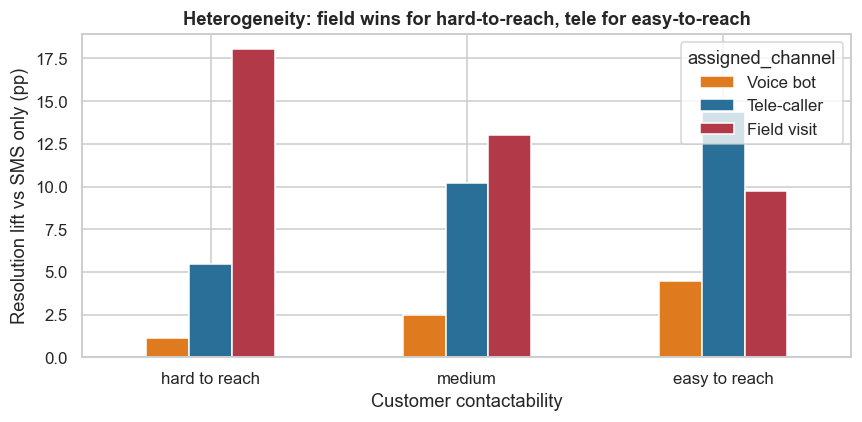

In [10]:
base_f = "resolved_30d ~ C(assigned_channel, Treatment('SMS only')) + paid_ratio_6m + broken_ptp_count + dpd + log_out + contactability + contact_missing + bnpl + card + tier3 + high_inc + age"
m0 = smf.logit(base_f, data=df).fit(disp=0)
het = []
for mod in ["contactability", "paid_ratio_6m", "log_out", "broken_ptp_count"]:
    m1 = smf.logit(base_f + f" + C(assigned_channel, Treatment('SMS only')):{mod}", data=df).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf); het.append((mod, lr, 3, stats.chi2.sf(lr, 3)))
het = pd.DataFrame(het, columns=["moderator", "LR χ²", "df", "p"]); het["p_holm"] = multipletests(het.p, method="holm")[1]
df["contact_band"] = pd.qcut(df.contactability, 3, labels=["hard to reach", "medium", "easy to reach"])
lift = df.groupby(["contact_band", "assigned_channel"], observed=True).resolved_30d.mean().unstack()[ARMS]
lift = lift[ARMS[1:]].sub(lift["SMS only"], axis=0) * 100
display(het.round(4))
fig, ax = plt.subplots(figsize=(8, 4)); lift.plot(kind="bar", ax=ax, color=[PAL[a] for a in ARMS[1:]])
ax.set_xlabel("Customer contactability"); ax.set_ylabel("Resolution lift vs SMS only (pp)"); ax.set_title("Heterogeneity: field wins for hard-to-reach, tele for easy-to-reach")
ax.tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()

**Takeaway / observation:** every moderator significantly changes channel effects after Holm correction: **contactability** (LR χ² = 260), **outstanding balance** (494), broken promises (29) and payment history (10.6, p = 0.014). The chart shows the pattern: **field visits help most for hard-to-reach customers**, while tele-calls work best for easy-to-reach ones, where the bot also helps a little. One channel rule for everyone leaves money on the table. That is the rationale for uplift modelling.

## 8. ML Section — T-learner uplift per channel, Qini curves, and propensity vs uplift

**T-learner:** one gradient-boosting classifier per arm (default hyper-parameters, no tuning; D-19-05), each trained on the training half of that arm. For each test account and channel, **predicted uplift** = P̂(resolve | channel) − P̂(resolve | SMS only). **Qini curves** (per channel, on the randomised test data) show the incremental resolutions captured when accounts are ranked by (a) predicted uplift vs (b) propensity. We also check predicted uplift against the **hidden true uplift** (simulation only).

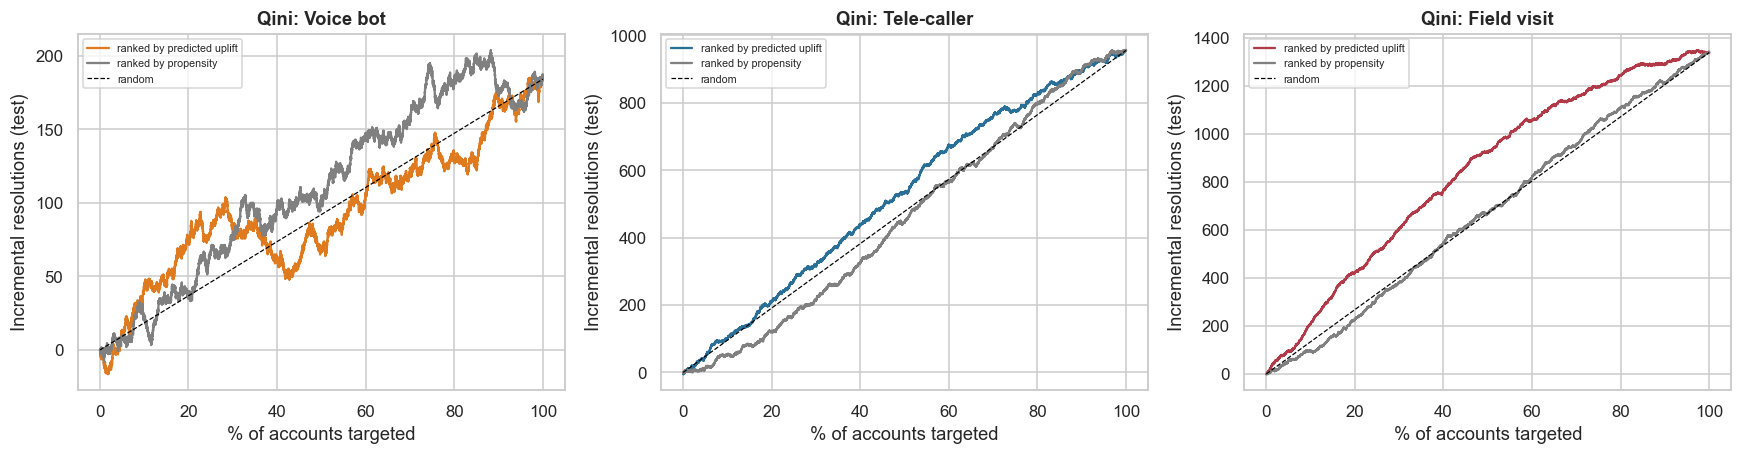

,channel,ranking,Qini coefficient,share of total uplift in top 20%
0,Voice bot,ranked by predicted uplift,0.0090,0.3970
1,Voice bot,ranked by propensity,0.0990,0.1910
2,Tele-caller,ranked by predicted uplift,0.0490,0.2200
3,Tele-caller,ranked by propensity,-0.0210,0.1280
4,Field visit,ranked by predicted uplift,0.1270,0.3160
5,Field visit,ranked by propensity,0.0010,0.1700


,"corr(predicted uplift, TRUE uplift)","corr(propensity, TRUE uplift)"
Voice bot,0.1320,0.2220
Tele-caller,0.3940,-0.1360
Field visit,0.7160,0.0100


In [11]:
FE = ["paid_ratio_6m", "broken_ptp_count", "dpd", "log_out", "log_overdue", "contactability", "contact_missing", "bnpl", "card", "tier3", "high_inc", "age"]
arm_models = {a: HistGradientBoostingClassifier(random_state=SEED).fit(train.loc[train.assigned_channel == a, FE], train.loc[train.assigned_channel == a, "resolved_30d"]) for a in ARMS}
for a in ARMS:
    test[f"p_{a}"] = arm_models[a].predict_proba(test[FE])[:, 1]
for a in ARMS[1:]:
    test[f"u_{a}"] = test[f"p_{a}"] - test["p_SMS only"]
true_map = {"Voice bot": "_p_bot", "Tele-caller": "_p_tele", "Field visit": "_p_field"}
def qini(d, arm, score):
    d = d[d.assigned_channel.isin([arm, "SMS only"])].sort_values(score, ascending=False)
    t = (d.assigned_channel == arm).values; y = d.resolved_30d.values
    ct, cc = np.cumsum(t), np.cumsum(~t); yt, yc = np.cumsum(y * t), np.cumsum(y * ~t)
    inc = yt - yc * np.divide(ct, cc, out=np.zeros(len(ct)), where=cc > 0)
    return np.arange(1, len(d) + 1) / len(d), inc
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3)); qrows = []
for ax, a in zip(axes, ARMS[1:]):
    for sc, c, lab in [(f"u_{a}", PAL[a], "ranked by predicted uplift"), ("propensity", "grey", "ranked by propensity")]:
        f, inc = qini(test, a, sc); ax.plot(f * 100, inc, color=c, label=lab)
        qrows.append((a, lab, np.trapezoid(inc - f * inc[-1], f) / max(abs(inc[-1]), 1), inc[int(0.2 * len(inc)) - 1] / inc[-1]))
    ax.plot([0, 100], [0, inc[-1]], "--", color="black", lw=0.8, label="random")
    ax.set_xlabel("% of accounts targeted"); ax.set_ylabel("Incremental resolutions (test)"); ax.set_title(f"Qini: {a}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
qtab = pd.DataFrame(qrows, columns=["channel", "ranking", "Qini coefficient", "share of total uplift in top 20%"])
corr = pd.DataFrame({a: [np.corrcoef(test[f"u_{a}"], test[true_map[a]] - test["_p_sms"])[0, 1], np.corrcoef(test["propensity"], test[true_map[a]] - test["_p_sms"])[0, 1]] for a in ARMS[1:]},
                    index=["corr(predicted uplift, TRUE uplift)", "corr(propensity, TRUE uplift)"]).T
display(qtab.round(3)); corr.round(3)

**Takeaway:** - **Field and tele:** ranking by predicted uplift captures far more incremental resolutions than ranking by propensity. For field, the top 20% by uplift capture **32%** of the total uplift vs **17%** by propensity (Qini 0.13 vs 0.00). For tele, **22% vs 13%** (Qini 0.05 vs −0.02: ranking tele by propensity is *worse than random*).
- **Bot:** the opposite. Propensity ranks better (Qini 0.10 vs 0.01), because the bot's true effect is small and tied to good payers who forgot. Our T-learner cannot estimate such a small effect well.
- **Check against hidden truth:** predicted uplift correlates 0.72 with the true field uplift and 0.39 with tele, but only 0.13 with bot. Propensity correlates **−0.14** with the true tele uplift. **Lesson:** uplift models work where effects are large and heterogeneous, and small effects need more data.

### 7.4 Optimal channel assignment under capacity: a linear program

For each test account *i* and channel *j*, the expected net value is:
> v_ij = overdue_i × [P̂(resolve | j) × r₁ⱼ + (1 − P̂(resolve | j)) × r₀ⱼ] − cost_j

where r₁ⱼ and r₀ⱼ are the average **share of the overdue amount** recovered when resolved / not resolved under channel j (training data). Value therefore scales with each account's balance. A first version used flat ₹ averages instead, which ignored balance and *lost* to the simple "largest balance first" rule. That is a useful lesson in itself (D-19-06). We then solve:
> maximise Σ v_ij x_ij subject to Σ_j x_ij = 1 for every account; Σ_i x_i,tele ≤ 20% of accounts; Σ_i x_i,field ≤ 4% of accounts; 0 ≤ x ≤ 1.

This is a **linear program** (scipy `linprog`, HiGHS solver). Its constraint matrix is totally unimodular, so the solution is integral (each account gets exactly one channel).
**Competing policies at the same capacity:**
- **Status quo:** field for the 4% largest balances, tele for the next 20% largest, bot for everyone else.
- **Propensity-based:** tele and field for the accounts with the highest propensity to pay (the common vendor approach), bot for the rest.
- **Uplift + LP (ours).**

In [12]:
cond = train.assign(share=train.amount_recovered_inr / train.overdue_inr).groupby(["assigned_channel", "resolved_30d"]).share.mean().unstack()
V = np.column_stack([test.overdue_inr * (test[f"p_{a}"] * cond.loc[a, 1] + (1 - test[f"p_{a}"]) * cond.loc[a, 0]) - COST[a] for a in ARMS])
print("Mean recovered share of overdue (columns: not resolved / resolved) by arm:"); print(cond.round(3))
n = len(test); k = len(ARMS)
c = -V.ravel()
A_eq = sparse.kron(sparse.eye(n), np.ones((1, k)), format="csr"); b_eq = np.ones(n)
rows_ub = []
for a in ["Tele-caller", "Field visit"]:
    j = ARMS.index(a); r_ = np.zeros(k); r_[j] = 1; rows_ub.append(sparse.kron(np.ones((1, n)), r_.reshape(1, -1)))
A_ub = sparse.vstack(rows_ub).tocsr(); b_ub = np.array([CAP["Tele-caller"] * n, CAP["Field visit"] * n])
lp = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=(0, 1), method="highs")
X = lp.x.reshape(n, k)
test["pi_uplift"] = np.array(ARMS)[X.argmax(1)]
print(f"LP status: {lp.message} | fractional solutions: {int(((X > 1e-6) & (X < 1 - 1e-6)).any(1).sum())}")
order_bal = np.argsort(-test.outstanding_inr.values); order_prop = np.argsort(-test.propensity.values)
def rank_policy(order):
    pol = np.full(n, "Voice bot", dtype=object); nf, nt = int(CAP["Field visit"] * n), int(CAP["Tele-caller"] * n)
    pol[order[:nf]] = "Field visit"; pol[order[nf:nf + nt]] = "Tele-caller"; return pol
test["pi_status_quo"] = rank_policy(order_bal); test["pi_propensity"] = rank_policy(order_prop); test["pi_all_bot"] = "Voice bot"
print("Uplift-LP channel mix:", test.pi_uplift.value_counts(normalize=True).round(3).to_dict())

Mean recovered share of overdue (columns: not resolved / resolved) by arm:
resolved_30d          0      1
assigned_channel              
Field visit      0.0790 0.8450
SMS only         0.0780 0.7500
Tele-caller      0.0780 0.7500
Voice bot        0.0780 0.7480


LP status: Optimization terminated successfully. (HiGHS Status 7: Optimal) | fractional solutions: 0
Uplift-LP channel mix: {'Voice bot': 0.475, 'SMS only': 0.285, 'Tele-caller': 0.2, 'Field visit': 0.04}


### 7.5 Off-policy evaluation: how much would each policy actually earn?

**(a) Why off-policy evaluation?** We cannot run every policy on the same customers. Because the experiment assigned channels **at random with known probabilities**, we can estimate any policy's value from the existing data by **inverse-probability weighting (IPW)**:
> V̂(π) = (1/n) Σ_i 1{A_i = π(x_i)} × (net ₹_i) / e(A_i)

where e(A) is the arm's assignment probability. We use the *actual* arm shares, which absorbs the small field-arm SRM. The estimate is unbiased for any policy. **CIs come from a paired bootstrap** (the same resampled accounts are used for every policy, so differences are precise). The **hidden truth** gives an oracle check (simulation only).

In [13]:
e = test.assigned_channel.map(df.assigned_channel.value_counts(normalize=True)).values
y_net = test.net_inr.values; y_res = test.resolved_30d.values; A = test.assigned_channel.values
POL = ["pi_all_bot", "pi_status_quo", "pi_propensity", "pi_uplift"]
LAB = {"pi_all_bot": "Bot for everyone", "pi_status_quo": "Status quo (by balance)", "pi_propensity": "Propensity-based", "pi_uplift": "Uplift + LP (ours)"}
def ipw(pol, idx):
    m = (A[idx] == test[pol].values[idx]) / e[idx]
    return (m * y_net[idx]).mean(), (m * y_res[idx]).mean(), (m * test[pol].map(COST).values[idx]).mean()
point = {p: ipw(p, np.arange(n)) for p in POL}
B = [RNG.integers(0, n, n) for _ in range(1000)]
boot = {p: np.array([ipw(p, b) for b in B]) for p in POL}
true_p = test[["_p_sms", "_p_bot", "_p_tele", "_p_field"]].values
def oracle_res(pol): return true_p[np.arange(n), [ARMS.index(a) for a in test[pol]]].mean()
ope = pd.DataFrame({LAB[p]: {"net ₹ / account (IPW)": point[p][0], "net CI low": np.percentile(boot[p][:, 0], 2.5), "net CI high": np.percentile(boot[p][:, 0], 97.5),
                             "resolution (IPW)": point[p][1], "TRUE resolution (oracle)": oracle_res(p), "cost ₹ / account": point[p][2]} for p in POL}).T
diffs = {f"Uplift − {LAB[p]}": boot["pi_uplift"][:, 0] - boot[p][:, 0] for p in ["pi_status_quo", "pi_propensity", "pi_all_bot"]}
dtab = pd.DataFrame({k_: {"Δ net ₹ / account": np.mean(v), "CI low": np.percentile(v, 2.5), "CI high": np.percentile(v, 97.5), "P(Δ ≤ 0)": np.mean(v <= 0)} for k_, v in diffs.items()}).T
display(ope.round(2)); dtab.round(2)

,net ₹ / account (IPW),net CI low,net CI high,resolution (IPW),TRUE resolution (oracle),cost ₹ / account
Bot for everyone,"3,943.1800","3,785.7700","4,110.7000",0.4100,0.4100,8.0000
Status quo (by balance),"4,663.7500","4,465.1000","4,867.1100",0.4300,0.4400,35.8800
Propensity-based,"3,986.2200","3,817.2400","4,152.9300",0.4200,0.4200,36.0600
Uplift + LP (ours),"4,565.3600","4,364.8100","4,774.7600",0.4200,0.4300,34.4300


,Δ net ₹ / account,CI low,CI high,P(Δ ≤ 0)
Uplift − Status quo (by balance),-98.6000,-320.8900,114.5800,0.8200
Uplift − Propensity-based,582.5300,320.1100,833.7800,0.0000
Uplift − Bot for everyone,620.7300,386.2500,877.8600,0.0000


**Diagnostic (simulation only): is the gap a model problem or a business reality?** We score every policy with the **hidden true** resolution probabilities (no sampling noise), and also solve the LP with the *true* probabilities. That **oracle policy** is the best any model could do. The distance between "Uplift + LP" and the oracle is the cost of imperfect uplift estimates. The distance between the oracle and the status quo is the real size of the prize.

In [14]:
TP = {"SMS only": "_p_sms", "Voice bot": "_p_bot", "Tele-caller": "_p_tele", "Field visit": "_p_field"}
Vt = np.column_stack([test.overdue_inr * (test[TP[a]] * cond.loc[a, 1] + (1 - test[TP[a]]) * cond.loc[a, 0]) - COST[a] for a in ARMS])
sol_o = linprog(-Vt.ravel(), A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=(0, 1), method="highs").x.reshape(n, k)
test["pi_oracle"] = np.array(ARMS)[sol_o.argmax(1)]
def true_value(pol): return Vt[np.arange(n), [ARMS.index(a) for a in test[pol]]].mean()
tv = pd.Series({**{LAB[p_]: true_value(p_) for p_ in POL}, "Oracle LP (true probabilities)": true_value("pi_oracle")}, name="TRUE expected net ₹ / account")
tv = tv.to_frame(); tv["gap to oracle"] = tv.iloc[:, 0] - tv.loc["Oracle LP (true probabilities)"].iloc[0]
agree = (test.pi_uplift == test.pi_oracle).mean()
print(f"Uplift-LP picks the same channel as the oracle for {agree:.1%} of accounts")
tv.round(1)

Uplift-LP picks the same channel as the oracle for 50.6% of accounts


,TRUE expected net ₹ / account,gap to oracle
Bot for everyone,"4,004.2000",-856.0000
Status quo (by balance),"4,700.7000",-159.4000
Propensity-based,"4,077.0000",-783.1000
Uplift + LP (ours),"4,654.3000",-205.8000
Oracle LP (true probabilities),"4,860.1000",0.0000


**Observation (diagnostic):** - With **true** probabilities, the oracle LP earns **₹4,860 per account**. The status quo (balance-first) earns **₹4,701**, only **₹159 (3.3%) below the optimum**. Our uplift-LP earns ₹4,654 (₹206 below), and propensity-based earns ₹4,077 (**₹783 below**).
- Uplift-LP picks the oracle's channel for only **51% of accounts**. The model, not the method, is the bottleneck.
- **Interpretation:** in this book, expected value is dominated by **balance** (field and tele lifts are fairly uniform across most accounts), so a balance rule is close to optimal. The remaining prize is real but modest (≈ 3%), and only a more accurate uplift model can capture it: bigger experiments, pooled learners (S/X-learners), and channel-specific features. **Propensity-based allocation is the one clearly bad choice.**

**(c)/(f) Observation:** - **IPW net ₹ per account (test half):** bot-for-everyone ₹3,943 · propensity-based ₹3,986 · **uplift + LP ₹4,565** (CI ₹4,365–4,775) · **status quo by balance ₹4,664**.
- **Uplift vs propensity: +₹583 per account (CI ₹320–834; P(Δ ≤ 0) ≈ 0)**, a decisive win over the vendor-style approach.
- **Uplift vs status quo by balance: −₹99 (CI −₹321 to +₹115), not significant.** We cannot claim the uplift policy beats simply sending humans to the largest balances.
- **Pre-registered decision rule:** "beat both alternatives with a CI excluding 0" is **not met** against the status quo, so **do not switch the routing engine yet**.

## 9. Business Translation — per 1 lakh delinquent accounts a month

Scale the IPW estimates (per account) to 1,00,000 accounts and compare each policy with the status quo on the vendor's documented KPIs: resolution rate, ₹ collected, and collection cost. Sensitivity: tele-caller cost ₹40 / ₹90 and field ₹300 / ₹600 (re-solving the LP), because cost assumptions drive the channel mix.

In [15]:
SCALE = 100_000
def kpis(pol, idx=np.arange(n)):
    m = (A[idx] == test[pol].values[idx]) / e[idx]
    rec = (m * test.amount_recovered_inr.values[idx]).mean(); res = (m * y_res[idx]).mean(); cost = test[pol].map(COST).values[idx].mean()
    return res, rec * SCALE / 1e7, cost * SCALE / 1e7, (rec - cost) * SCALE / 1e7
kp = pd.DataFrame({LAB[p]: dict(zip(["resolution", "₹ crore recovered", "₹ crore cost", "₹ crore net"], kpis(p))) for p in POL}).T
sq = kp.loc["Status quo (by balance)"]
kp["Δ resolution vs status quo"] = kp.resolution / sq.resolution - 1
kp["Δ collections vs status quo"] = kp["₹ crore recovered"] / sq["₹ crore recovered"] - 1
kp["Δ cost vs status quo"] = kp["₹ crore cost"] / sq["₹ crore cost"] - 1
display(kp.round(3))
sens = []
for lab_, tc_, fc_ in [("Cheap humans (tele ₹40, field ₹300)", 40, 300), ("Base (₹60, ₹450)", 60, 450), ("Expensive humans (tele ₹90, field ₹600)", 90, 600)]:
    cost_ = {"SMS only": 2, "Voice bot": 8, "Tele-caller": tc_, "Field visit": fc_}
    V_ = np.column_stack([test.overdue_inr * (test[f"p_{a}"] * cond.loc[a, 1] + (1 - test[f"p_{a}"]) * cond.loc[a, 0]) - cost_[a] for a in ARMS])
    sol = linprog(-V_.ravel(), A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=(0, 1), method="highs").x.reshape(n, k)
    pol_ = np.array(ARMS)[sol.argmax(1)]
    net_up = (((A == pol_) / e) * (test.amount_recovered_inr.values - pd.Series(A).map(cost_).values)).mean()
    sq_pol = test.pi_status_quo.values
    net_sq = (((A == sq_pol) / e) * (test.amount_recovered_inr.values - pd.Series(A).map(cost_).values)).mean()
    sens.append((lab_, net_sq * SCALE / 1e7, net_up * SCALE / 1e7, (net_up - net_sq) * SCALE / 1e7, (pol_ == "Tele-caller").mean(), (pol_ == "Field visit").mean()))
pd.DataFrame(sens, columns=["scenario", "status quo net ₹ cr", "uplift-LP net ₹ cr", "gain ₹ cr / month", "tele share used", "field share used"]).set_index("scenario").round(3)

,resolution,₹ crore recovered,₹ crore cost,₹ crore net,Δ resolution vs status quo,Δ collections vs status quo,Δ cost vs status quo
Bot for everyone,0.4070,39.5120,0.0800,39.4320,-0.0540,-0.1590,-0.7780
Status quo (by balance),0.4310,46.9960,0.3610,46.6360,0.0000,0.0000,0.0000
Propensity-based,0.4230,40.2230,0.3610,39.8620,-0.0180,-0.1440,0.0000
Uplift + LP (ours),0.4220,45.9980,0.3440,45.6540,-0.0210,-0.0210,-0.0470


,status quo net ₹ cr,uplift-LP net ₹ cr,gain ₹ cr / month,tele share used,field share used
scenario,,,,,
"Cheap humans (tele ₹40, field ₹300)",46.7370,45.7540,-0.9830,0.2000,0.0400
"Base (₹60, ₹450)",46.6380,45.6540,-0.9840,0.2000,0.0400
"Expensive humans (tele ₹90, field ₹600)",46.5180,45.5330,-0.9850,0.2000,0.0400


**Business reading:** - **Per 1 lakh delinquent accounts a month (IPW):** status quo by balance **₹46.6 crore net** (₹47.0 crore recovered, ₹0.36 crore contact cost) · uplift-LP **₹45.7 crore** (−2%, cost −4.7%) · propensity-based **₹39.9 crore (−14% collections at the same cost)** · bot-for-everyone ₹39.4 crore.
- **Versus "no human targeting" (bot for everyone):** balance- or uplift-based routing lifts collections by **≈ +16–19%**, the same order as the vendor's claimed "+25% improved collections". Such claims are plausible *relative to an unoptimised baseline*. Our simulation cannot confirm the claimed −40% cost, because costs here are set by capacity, not by the model.
- **Sensitivity:** across cheaper and dearer human costs (tele ₹40–90, field ₹300–600), the uplift-vs-status-quo gap stays at about −₹1 crore a month. Capacity, not price, binds the allocation.
- **The remaining prize:** reaching the oracle would add ≈ ₹159 per account, about **₹1.6 crore a month per lakh accounts**. That is the business case for investing in a continuous experimentation programme.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** uplift beats propensity (✅ CI excludes 0) but not the balance-based status quo (❌ CI −₹321 to +₹115). **Do not replace the current routing yet. Do retire propensity-based routing anywhere it is used.**

**I recommend:**
1. **Never allocate scarce human contact by propensity to pay.** It costs ≈ 16% of net recovery in this book.
2. **Keep value-based routing:** field visits to large, hard-to-reach balances; tele-calls to contactable, mid-risk accounts. Use the **voice bot** for everyone else instead of SMS only (+₹270 per account at ₹8).
3. **Build the uplift capability properly:** keep a continuous **10% randomised slice** across channels, refit uplift models monthly, and try pooled learners (S/X-learners) and richer contact-history features. Re-run this off-policy evaluation quarterly and switch when the CI vs status quo clears zero. The prize is ≈ 3% (≈ ₹1.6 crore a month per lakh accounts).
4. **Fix the field-app sync** that caused the borderline SRM, and add a daily SRM check to the experiment.

**KPIs:** resolution rate and net ₹ per account by channel (randomised slice); off-policy value of champion vs challenger with CIs; channel capacity utilisation; cost per ₹ recovered; complaints per 1,000 contacts by channel (conduct guardrail); SRM p-value per experiment month.

## 11. Risks, Limitations and Next Steps

- **Synthetic data, vendor claims:** the source's figures are vendor-reported and aggregated (weak evidence). Our simulation shows *how* such gains arise, not that they generalise. Any lender should verify on its own randomised experiment.
- **Experiments in collections need care:** randomising *less* contact for some customers can raise losses in the short run. Keep the experimental share small (e.g., 10–20%), stratify by risk, and pre-agree stopping rules.
- **Conduct and regulation:** RBI's Fair Practices Code and recovery-agent guidelines restrict calling hours, frequency and conduct. Optimisation must sit *inside* those rules: it decides which channel, never more pressure. Track complaints per 1,000 contacts by channel as a guardrail.
- **Model drift:** uplift changes with seasons (salary week, festivals) and with caller scripts and teams. Re-run a randomised slice monthly and re-fit.
- **Next steps:** (1) sequential multi-touch policies (bot first, then human for non-responders) via a small contextual bandit; (2) add timing (salary-day) and language-matched caller assignment; (3) extend to pre-delinquency nudges for accounts predicted to roll (link to Case 12).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Channel effect (ATE) | p̂_channel − p̂_SMS, Newcombe CI |
| T-learner uplift | τ̂_j(x) = P̂_j(resolve \| x) − P̂_SMS(resolve \| x) |
| Qini | Q(k) = Y_t(k) − Y_c(k) · N_t(k)/N_c(k) |
| Expected net value | v_ij = overdue_i · [p̂_ij r₁ⱼ + (1 − p̂_ij) r₀ⱼ] − c_j |
| LP | max Σ v_ij x_ij s.t. Σ_j x_ij = 1, Σ_i x_ij ≤ cap_j, 0 ≤ x ≤ 1 |
| IPW policy value | V̂(π) = mean[1{A = π(x)} · R / e(A)] |

| Term | Meaning |
|---|---|
| Propensity-to-pay | Probability a customer pays with the default (cheapest) treatment. |
| Uplift | Extra probability of paying *caused* by a channel. |
| Sure thing / lost cause / persuadable | Pays anyway / never pays / pays only if contacted. |
| T-learner | One model per treatment arm; uplift = difference of predictions. |
| Linear program | An optimisation with linear objective and constraints; here it assigns channels under capacity. |
| Off-policy evaluation | Estimating a new policy's results from data collected under randomisation. |
| SRM | Sample-ratio mismatch: arm sizes differ from the design. |